# Exercise 2: Principal Component Analysis

**Subject:** Machine Learning Lab  
**Topic:** Principal Component Analysis (PCA)

## Aim
To implement Principal Component Analysis (PCA) to reduce the dimensionality of a dataset, identify the most important components, and visualize the explained variance.

Original Dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Original number of features: 4
Number of samples: 150

PCA-transformed dataset:


,Principal Component 1,Principal Component 2,Species
0,-2.264703,0.480027,setosa
1,-2.080961,-0.674134,setosa
2,-2.364229,-0.341908,setosa
3,-2.299384,-0.597395,setosa
4,-2.389842,0.646835,setosa



Explained variance ratio:
[0.72962445 0.22850762]
Total variance retained: 95.81 %


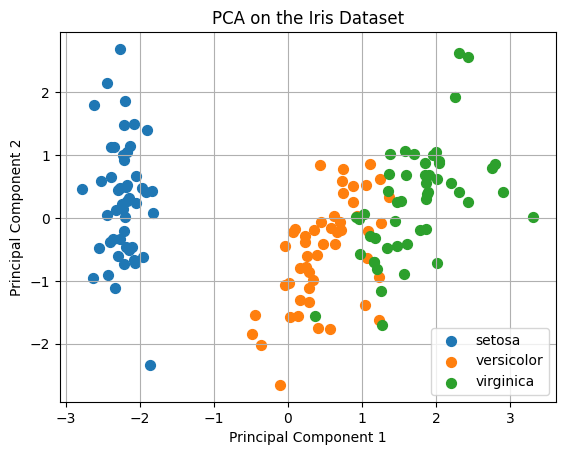

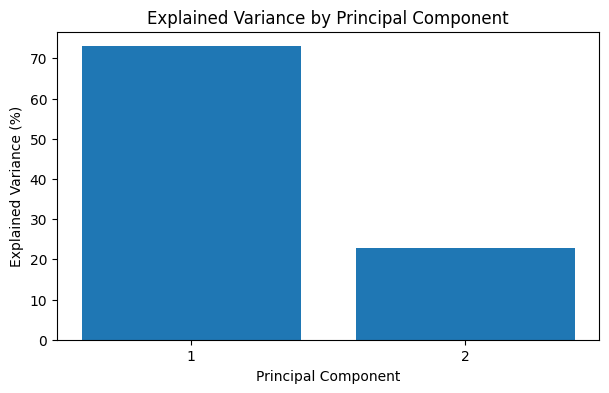

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df["Species"] = [iris.target_names[i] for i in y]

print("Original Dataset:")
display(df.head())

print("Original number of features:", X.shape[1])
print("Number of samples:", X.shape[0])

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA to reduce four features to two components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"]
)
pca_df["Species"] = [iris.target_names[i] for i in y]

print("\nPCA-transformed dataset:")
display(pca_df.head())

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print(
    "Total variance retained:",
    round(np.sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

# Plot the observations using the first two components
for species in iris.target_names:
    subset = pca_df[pca_df["Species"] == species]
    plt.scatter(
        subset["Principal Component 1"],
        subset["Principal Component 2"],
        label=species,
        s=50
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA on the Iris Dataset")
plt.legend()
plt.grid(True)
plt.show()

# Plot explained variance
plt.figure(figsize=(7, 4))
components = np.arange(1, len(pca.explained_variance_ratio_) + 1)
plt.bar(components, pca.explained_variance_ratio_ * 100)
plt.xticks(components)
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("Explained Variance by Principal Component")
plt.show()

## Result

Principal Component Analysis (PCA) was successfully implemented on the Iris dataset. The original four features were reduced to two principal components after standardizing the data.

- **Dataset:** Iris dataset
- **Total samples:** 150
- **Original features:** 4
- **Reduced features:** 2
- **Variance explained by PC1:** 72.96%
- **Variance explained by PC2:** 22.85%
- **Total variance retained:** 95.81%

The scatter plot visualizes the three Iris species using the two principal components, while the explained variance graph shows the contribution of each component.

## Conclusion

PCA successfully reduced the dimensionality of the Iris dataset from four features to two while retaining 95.81% of the total variance. The visualization demonstrates how dimensionality reduction can simplify data analysis while preserving most of the important information.